In [17]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from shapely.geometry import Point
import pandas as pd
import numpy as np

In [2]:
df_rm = gpd.read_file('Microdatos_Manzana.shp')

In [ ]:
df_quilicura = df_rm[df_rm['COMUNA'] == 'QUILICURA']

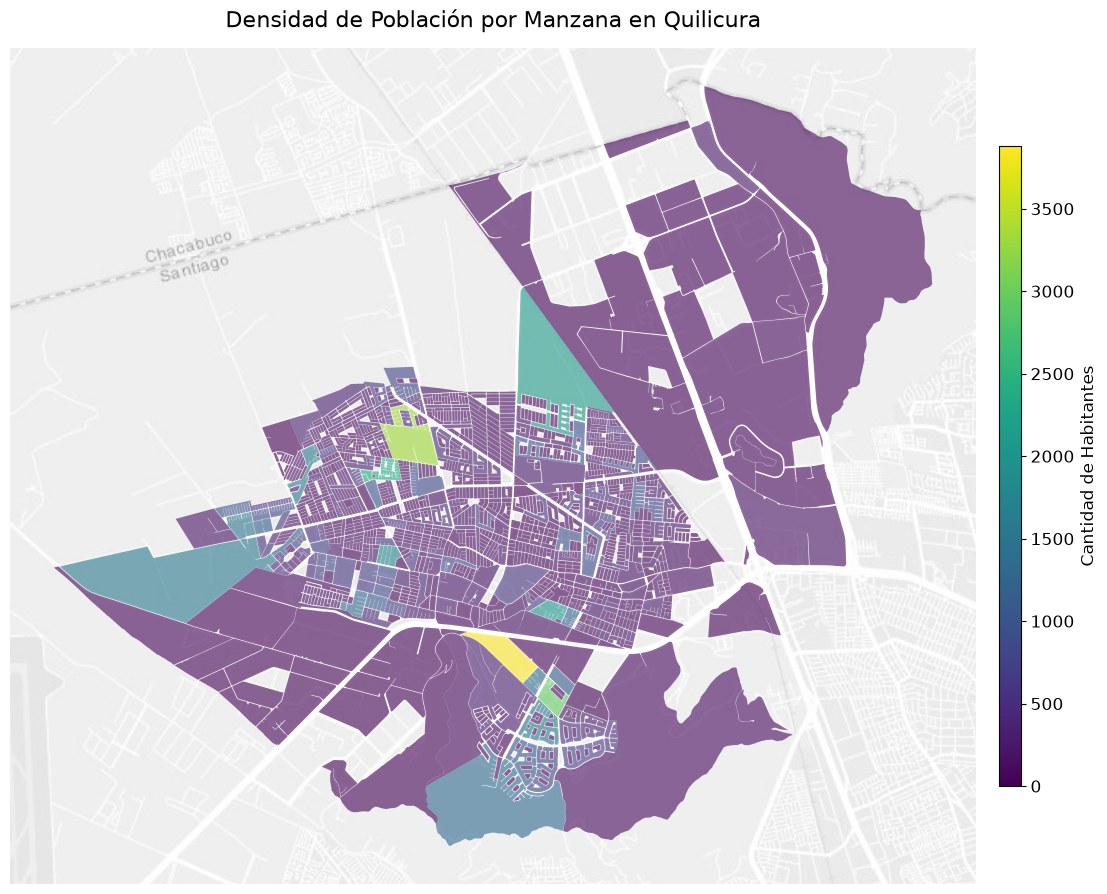

In [ ]:
df_quilicura_web = df_quilicura.to_crs(epsg=3857)

plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(figsize=(12, 12))

# 3. Dibujar las manzanas (El mapa de calor)
df_quilicura_web.plot(
    ax=ax,
    column='TOTAL_PERS',    
    cmap='viridis',           
    alpha=0.6,              
    edgecolor='none',        
    legend=True,
    legend_kwds={
        'label': "Cantidad de Habitantes",
        'shrink': 0.55,   # Achica el alto de la barra 
        'aspect': 30,     # adelgazar la barra
        'pad': 0.02       # La acerca un poquito más al mapa
    }
)

# 4. Agregar el mapa base 
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, attribution=False)

ax.set_axis_off()  # Apagar las coordenadas numéricas de los bordes
plt.title('Densidad de Población por Manzana en Quilicura', fontsize=16, pad=15)

plt.tight_layout()
plt.show()

In [18]:
# 1. Crear el punto de la Notaría (Ojo: siempre va Longitud primero, luego Latitud)
lon_notaria = -70.729
lat_notaria = -33.364
punto_notaria = Point(lon_notaria, lat_notaria)

# Convertir el punto a un formato GeoPandas y alinearlo al mapa de metros (EPSG:3857)
gdf_notaria = gpd.GeoDataFrame(geometry=[punto_notaria], crs="EPSG:4326")
notaria_geom = gdf_notaria.to_crs(epsg=3857).geometry.iloc[0]

# 2. Calcular la distancia desde el centro de cada manzana a la notaría
# .centroid encuentra el centro de gravedad de cada cuadra
df_quilicura_web['distancia_notaria_m'] = df_quilicura_web.geometry.centroid.distance(notaria_geom)

In [19]:
# 3. Definir los límites de los bins (en metros)
bins = [0, 500, 1000, 1500, 2000, 3000, 5000, np.inf]
etiquetas = ['0-500m', '500m-1km', '1-1.5km', '1.5-2km', '2-3km', '3-5km', '+5km']

# Clasificar cada manzana en un tramo
df_quilicura_web['tramo_cercania'] = pd.cut(
    df_quilicura_web['distancia_notaria_m'], 
    bins=bins, 
    labels=etiquetas
)

# 4. Agrupar y sumar la población
poblacion_por_tramo = df_quilicura_web.groupby('tramo_cercania')['TOTAL_PERS'].sum()

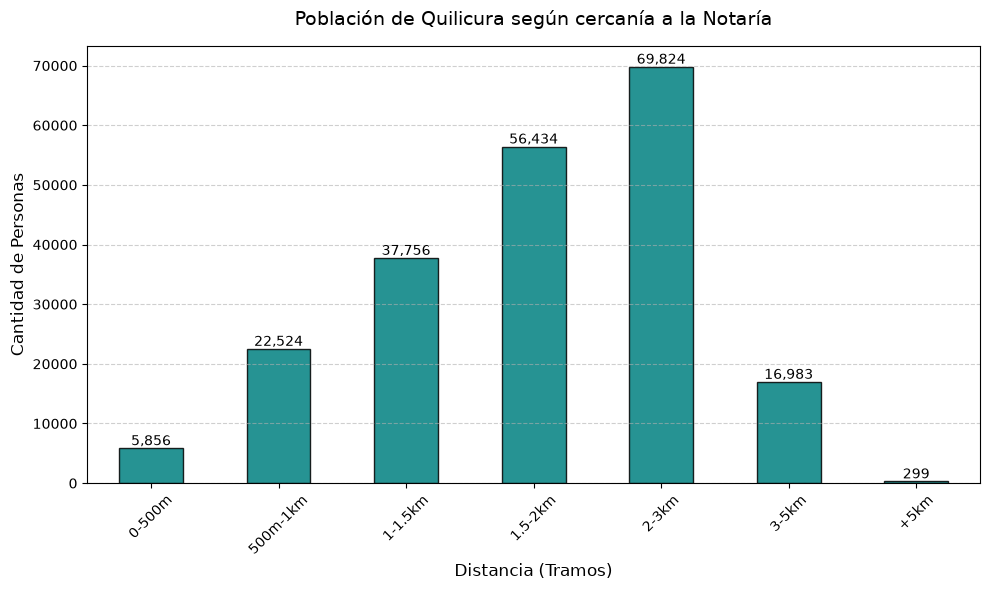

In [21]:
# 5. Graficar
fig, ax = plt.subplots(figsize=(10, 6))

poblacion_por_tramo.plot(
    kind='bar', 
    ax=ax, 
    color='teal',        # Un color que resalte
    edgecolor='black', 
    alpha=0.85
)

# Estética del gráfico
ax.set_title('Población de Quilicura según cercanía a la Notaría', fontsize=14, pad=15)
ax.set_xlabel('Distancia (Tramos)', fontsize=12)
ax.set_ylabel('Cantidad de Personas', fontsize=12)

# Girar las etiquetas de abajo para que se lean bien
plt.xticks(rotation=45)

# Agregar líneas de referencia horizontales
ax.grid(axis='y', linestyle='--', alpha=0.6)

# (Opcional) Poner los números exactos arriba de cada barra
for index, value in enumerate(poblacion_por_tramo):
    ax.text(index, value + 500, f'{int(value):,}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

In [32]:
print(df_quilicura_web.columns.tolist())

['CUT', 'REGION', 'PROVINCIA', 'COMUNA', 'NOMBRE_DIS', 'CODIGO_DIS', 'MANZENT', 'ZONA_CENSA', 'MANZANA', 'TOTAL_PERS', 'TOTAL_HOMB', 'TOTAL_MUJE', 'PERSONAS_0', 'PERSONAS_6', 'PERSONAS_1', 'PERSONAS_M', 'PERSONAS_E', 'PUEBLOS_IN', 'TOTAL_VIV_', 'TOTAL_VIV1', 'VIV_OCUPA_', 'TOTAL_VIVI', 'CANTIDAD_H', 'VIV_TIPO_C', 'VIV_TIPO_D', 'VIV_TIPO_T', 'VIV_TIPO_P', 'VIV_TIPO_M', 'VIV_TIPO_1', 'VIV_TIPO_O', 'VIV_PARED_', 'VIV_PARED1', 'VIV_PARE_1', 'VIV_PARE_2', 'VIV_PARE_3', 'VIV_PARE_4', 'VIV_TECHO_', 'VIV_TECHO1', 'VIV_TECH_1', 'VIV_TECH_2', 'VIV_TECH_3', 'VIV_TECH_4', 'VIV_TECH_5', 'VIV_PISO_P', 'VIV_PISO_R', 'VIV_PISO_B', 'VIV_PISO_C', 'VIV_PISO_T', 'VIV_MATERI', 'VIV_MATE_1', 'VIV_MATE_2', 'VIV_AGUA_R', 'VIV_AGUA_P', 'VIV_AGUA_C', 'VIV_AGUA_1', 'geometry']


In [27]:
# Reemplaza estos nombres por los exactos que te imprimió el paso anterior
columnas_analisis = [
    'TOTAL_HOMB',
    'TOTAL_MUJE', 
    'PERSONAS_0', 
    'PERSONAS_6', 
    'PERSONAS_1', 
    'PERSONAS_M',
    'PERSONAS_E'  
]
# 1. Forzar la conversión a números (los textos como 'Indeterminado' se volverán nulos / NaN)
for col in columnas_analisis:
    df_quilicura_web[col] = pd.to_numeric(df_quilicura_web[col], errors='coerce')

# 2. Rellenar esos valores nulos con 0 para que no afecten la suma de personas
df_quilicura_web[columnas_analisis] = df_quilicura_web[columnas_analisis].fillna(0)

# 3. Ahora sí, hacemos la agrupación matemática real
tabla_resumen = df_quilicura_web.groupby('tramo_cercania', observed=False)[columnas_analisis].sum()

# (Opcional) Renombrar columnas si quieres
# tabla_resumen = tabla_resumen.rename(...)

# 4. Mostrar la tabla corregida
display(tabla_resumen)

,TOTAL_HOMB,TOTAL_MUJE,PERSONAS_0,PERSONAS_6,PERSONAS_1,PERSONAS_M,PERSONAS_E
tramo_cercania,,,,,,,
0-500m,2857.0,2999.0,253.0,412.0,4345.0,461.0,220.0
500m-1km,11002.0,11522.0,1404.0,2519.0,16318.0,1707.0,1243.0
1-1.5km,18386.0,19370.0,2517.0,5200.0,27037.0,2211.0,1886.0
1.5-2km,27724.0,28704.0,4131.0,7583.0,40315.0,2867.0,3906.0
2-3km,34484.0,35340.0,5198.0,10096.0,49982.0,2131.0,6150.0
3-5km,8386.0,8586.0,1528.0,2557.0,12087.0,582.0,1407.0
+5km,160.0,139.0,32.0,34.0,218.0,10.0,148.0


In [ ]:
"tabla_resumen.to_excel('Quilicura_Notaria_Demografia.xlsx')"